In [1]:
import pandas as pd
import numpy as np
import time
from scipy.optimize import minimize, Bounds

# Load input data
data = pd.read_excel('data/input42u.xlsx')
a = data['a'].values
b = data['b'].values
c = data['c'].values
Minimum_Capacity = data['pmin'].values
Maximum_Capacity = data['pmax'].values
ramp_up = data['rampup'].values
ramp_down = data['rampdown'].values
Unit = data['Unit'].values

penalty_factor = 1e6

# Load power demand
power_demand_data = pd.read_excel('data/power_demand42u.xlsx')
power_demand = power_demand_data['load'].values

# Cost function with penalty
def calculate_fuel_cost_with_penalty(P, a, b, c, demand):
    squaredP = np.multiply(P, P)
    Fuel_Cost = np.divide(np.add(a, np.multiply(b, P) + np.multiply(c, squaredP)), 1000)
    power_difference = np.sum(P) - demand
    penalty_term = penalty_factor * abs(power_difference)
    total_Fuel_Cost = np.sum(Fuel_Cost) + penalty_term
    return total_Fuel_Cost

# CG optimization wrapper
def cg(func, initial_guess, bounds):
    result = minimize(
        fun=func,
        x0=initial_guess,
        bounds=bounds,
        method='CG'
    )
    return result.x, result.fun

# Main optimization loop
all_outputs = []
schedulling = []

for load_counter, demand in enumerate(power_demand, start=1):
    start_time = time.time()
    if load_counter == 1:
        previous_output = None
    else:
        previous_output = all_outputs[-1]['Output']['Power Produced (MW)'].values

    initial_guess = (Minimum_Capacity + Maximum_Capacity) / 2
    bounds = list(zip(Minimum_Capacity, Maximum_Capacity))

    def objective(P):
        return calculate_fuel_cost_with_penalty(P, a, b, c, demand)

    P_opt, cost = cg(objective, initial_guess, bounds)

    # Enforce capacity and power balance
    for _ in range(10):
        P_opt = np.minimum(np.maximum(P_opt, Minimum_Capacity), Maximum_Capacity)
        power_difference = np.sum(P_opt) - demand
        if power_difference > 0:
            for j in range(len(P_opt)):
                if P_opt[j] > Minimum_Capacity[j]:
                    reduction = min(P_opt[j] - Minimum_Capacity[j], power_difference)
                    P_opt[j] -= reduction
                    power_difference -= reduction
        elif power_difference < 0:
            for j in range(len(P_opt)):
                if P_opt[j] < Maximum_Capacity[j]:
                    increase = min(Maximum_Capacity[j] - P_opt[j], abs(power_difference))
                    P_opt[j] += increase
                    power_difference += increase

    end_time = time.time()

    output = pd.DataFrame({'Unit': Unit, 'Power Produced (MW)': P_opt})
    print("Load Counter: {}".format(load_counter))
    print(f"Output for Power Demand {demand:.2f} MW")
    print(output)
    print(f"Total Power Produced: {np.sum(P_opt):.2f} MW")
    print(f'Total Fuel Cost: Rp {cost}')
    print(f'Computation Time: {end_time - start_time} seconds')
    print('------------------------------------------------\n')

    all_outputs.append({
        'Demand': demand,
        'Output': output,
        'Total Power Produced': np.sum(P_opt),
        'Total Fuel Cost': cost,
        'Computation Time': end_time - start_time
    })

    output_info = {'Demand': demand}
    for unit_index, unit in enumerate(Unit):
        output_info[f'Unit {unit} Power Produced'] = P_opt[unit_index]
        output_info[f'Unit {unit} Cost'] = cost
    schedulling.append(output_info)

# Ramp rate and generation limit check
ramp_rates = []
generation_limits = []
for i in range(1, len(power_demand)):
    prev = all_outputs[i - 1]['Output']['Power Produced (MW)'].values
    curr = all_outputs[i]['Output']['Power Produced (MW)'].values
    ramp_rate = curr - prev
    violations = np.logical_or(ramp_rate > ramp_up, ramp_rate < -ramp_down)

    ramp_rate_info = {'Demand': power_demand[i]}
    generation_limit_info = {'Demand': power_demand[i]}
    for unit_index, unit in enumerate(Unit):
        ramp_rate_info[f'Unit {unit}'] = ramp_rate[unit_index]
        ramp_rate_info[f'Unit {unit} Violation'] = violations[unit_index]
        gen_violation = (curr[unit_index] < Minimum_Capacity[unit_index]) or (curr[unit_index] > Maximum_Capacity[unit_index])
        generation_limit_info[f'Unit {unit}'] = curr[unit_index]
        generation_limit_info[f'Unit {unit} Violation'] = gen_violation
    ramp_rates.append(ramp_rate_info)
    generation_limits.append(generation_limit_info)

# Save to Excel
output_file_path = 'CG (ED).xlsx'
with pd.ExcelWriter(output_file_path) as writer:
    pd.DataFrame(schedulling).to_excel(writer, sheet_name='Schedulling', index=False)
    pd.DataFrame(all_outputs).to_excel(writer, sheet_name='Summary', index=False)
    pd.DataFrame(ramp_rates).to_excel(writer, sheet_name='Ramp Rates', index=False)
    pd.DataFrame(generation_limits).to_excel(writer, sheet_name='Generation Limits', index=False)

print("All results saved to 'CG (ED).xlsx'")

/var/folders/th/s6s5rhk92_319jmpt7c9n_cw0000gn/T/ipykernel_2017/1309072413.py:34: RuntimeWarning: Method CG cannot handle bounds.
  result = minimize(
/var/folders/th/s6s5rhk92_319jmpt7c9n_cw0000gn/T/ipykernel_2017/1309072413.py:34: RuntimeWarning: Method CG cannot handle bounds.
  result = minimize(
/var/folders/th/s6s5rhk92_319jmpt7c9n_cw0000gn/T/ipykernel_2017/1309072413.py:34: RuntimeWarning: Method CG cannot handle bounds.
  result = minimize(
/var/folders/th/s6s5rhk92_319jmpt7c9n_cw0000gn/T/ipykernel_2017/1309072413.py:34: RuntimeWarning: Method CG cannot handle bounds.
  result = minimize(
/var/folders/th/s6s5rhk92_319jmpt7c9n_cw0000gn/T/ipykernel_2017/1309072413.py:34: RuntimeWarning: Method CG cannot handle bounds.
  result = minimize(
/var/folders/th/s6s5rhk92_319jmpt7c9n_cw0000gn/T/ipykernel_2017/1309072413.py:34: RuntimeWarning: Method CG cannot handle bounds.
  result = minimize(
/var/folders/th/s6s5rhk92_319jmpt7c9n_cw0000gn/T/ipykernel_2017/1309072413.py:34: RuntimeWarni

Load Counter: 1
Output for Power Demand 8761.42 MW
    Unit  Power Produced (MW)
0      1           250.000000
1      2           250.000000
2      3           250.000000
3      4           250.000000
4      5           408.000000
5      6           422.020892
6      7           444.336831
7      8           100.320579
8      9           100.322540
9     10           100.322540
10    11           100.320579
11    12            40.000000
12    13            40.000000
13    14            88.563468
14    15            88.563468
15    16           304.870944
16    17           304.870944
17    18           304.870944
18    19             5.000000
19    20             5.000000
20    21            60.000000
21    22            60.000000
22    23            60.000000
23    24            60.000000
24    25            60.000000
25    26            60.000000
26    27            60.000000
27    28            60.000000
28    29           478.252530
29    30           478.252530
30    31           

/var/folders/th/s6s5rhk92_319jmpt7c9n_cw0000gn/T/ipykernel_2017/1309072413.py:34: RuntimeWarning: Method CG cannot handle bounds.
  result = minimize(
/var/folders/th/s6s5rhk92_319jmpt7c9n_cw0000gn/T/ipykernel_2017/1309072413.py:34: RuntimeWarning: Method CG cannot handle bounds.
  result = minimize(
/var/folders/th/s6s5rhk92_319jmpt7c9n_cw0000gn/T/ipykernel_2017/1309072413.py:34: RuntimeWarning: Method CG cannot handle bounds.
  result = minimize(
/var/folders/th/s6s5rhk92_319jmpt7c9n_cw0000gn/T/ipykernel_2017/1309072413.py:34: RuntimeWarning: Method CG cannot handle bounds.
  result = minimize(
/var/folders/th/s6s5rhk92_319jmpt7c9n_cw0000gn/T/ipykernel_2017/1309072413.py:34: RuntimeWarning: Method CG cannot handle bounds.
  result = minimize(
/var/folders/th/s6s5rhk92_319jmpt7c9n_cw0000gn/T/ipykernel_2017/1309072413.py:34: RuntimeWarning: Method CG cannot handle bounds.
  result = minimize(
/var/folders/th/s6s5rhk92_319jmpt7c9n_cw0000gn/T/ipykernel_2017/1309072413.py:34: RuntimeWarni

Load Counter: 15
Output for Power Demand 9234.13 MW
    Unit  Power Produced (MW)
0      1           250.000000
1      2           250.000000
2      3           273.845248
3      4           281.751583
4      5           457.468473
5      6           457.468473
6      7           457.468473
7      8           108.876572
8      9           108.877279
9     10           108.877279
10    11           108.876572
11    12            40.000000
12    13            40.000000
13    14            98.012417
14    15            98.012417
15    16           317.436227
16    17           317.436227
17    18           317.436227
18    19             5.000000
19    20             5.000000
20    21            67.075156
21    22            67.075156
22    23            67.075156
23    24            67.075864
24    25            67.075864
25    26            67.075864
26    27            67.075864
27    28            67.075864
28    29           492.799794
29    30           492.799794
30    31          

/var/folders/th/s6s5rhk92_319jmpt7c9n_cw0000gn/T/ipykernel_2017/1309072413.py:34: RuntimeWarning: Method CG cannot handle bounds.
  result = minimize(
/var/folders/th/s6s5rhk92_319jmpt7c9n_cw0000gn/T/ipykernel_2017/1309072413.py:34: RuntimeWarning: Method CG cannot handle bounds.
  result = minimize(
/var/folders/th/s6s5rhk92_319jmpt7c9n_cw0000gn/T/ipykernel_2017/1309072413.py:34: RuntimeWarning: Method CG cannot handle bounds.
  result = minimize(
/var/folders/th/s6s5rhk92_319jmpt7c9n_cw0000gn/T/ipykernel_2017/1309072413.py:34: RuntimeWarning: Method CG cannot handle bounds.
  result = minimize(
/var/folders/th/s6s5rhk92_319jmpt7c9n_cw0000gn/T/ipykernel_2017/1309072413.py:34: RuntimeWarning: Method CG cannot handle bounds.
  result = minimize(
/var/folders/th/s6s5rhk92_319jmpt7c9n_cw0000gn/T/ipykernel_2017/1309072413.py:34: RuntimeWarning: Method CG cannot handle bounds.
  result = minimize(
/var/folders/th/s6s5rhk92_319jmpt7c9n_cw0000gn/T/ipykernel_2017/1309072413.py:34: RuntimeWarni

Load Counter: 24
Output for Power Demand 10030.30 MW
    Unit  Power Produced (MW)
0      1           371.500000
1      2           371.500000
2      3           371.500000
3      4           371.500000
4      5           575.000000
5      6           575.000000
6      7           575.000000
7      8           174.600000
8      9           174.600000
9     10           174.600000
10    11           174.600000
11    12            80.000000
12    13            80.000000
13    14           170.000000
14    15           170.000000
15    16           454.753919
16    17           220.000000
17    18           220.000000
18    19            16.000000
19    20            16.000000
20    21           118.500000
21    22           118.500000
22    23           118.500000
23    24           118.500000
24    25           118.500000
25    26           118.500000
26    27           118.500000
27    28           118.500000
28    29           400.000000
29    30           400.000000
30    31         

Running F01 (dim=30)...


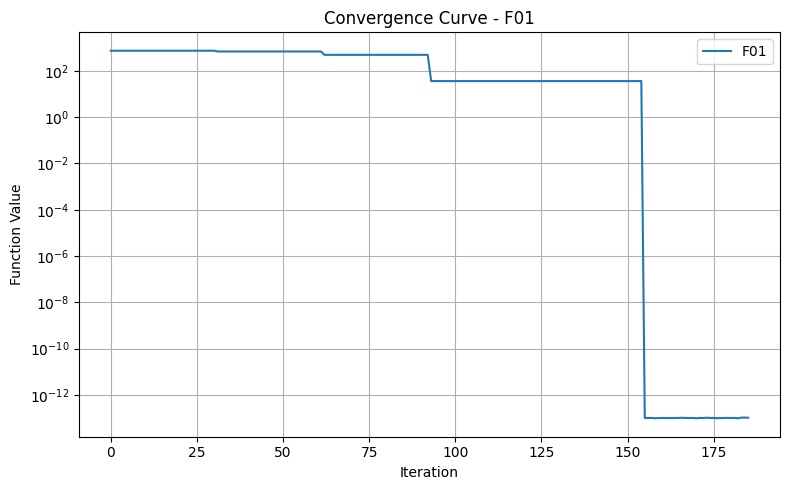

Running F02 (dim=30)...


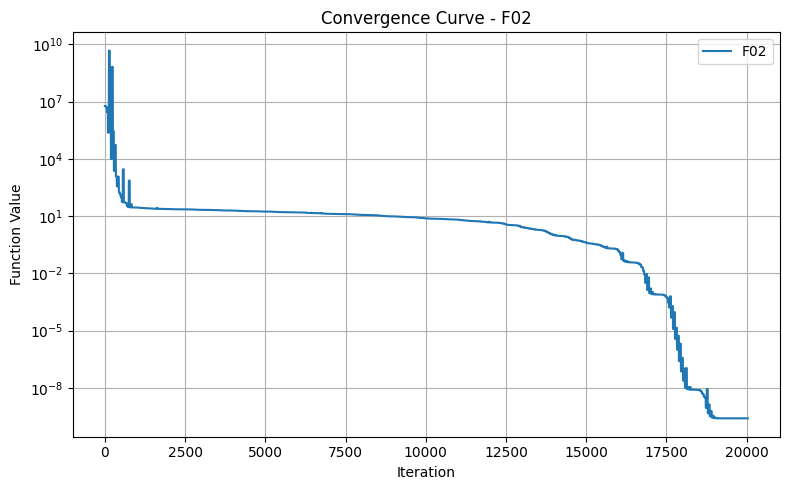

Running F03 (dim=30)...


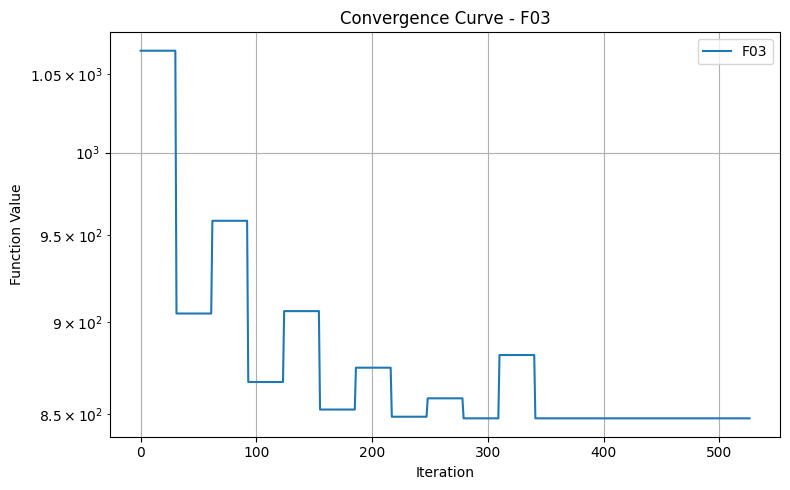

Running F04 (dim=30)...


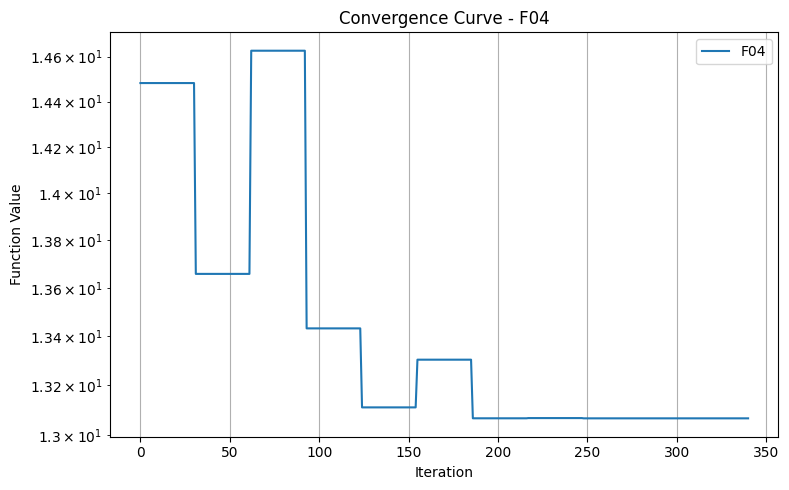

Running F05 (dim=30)...


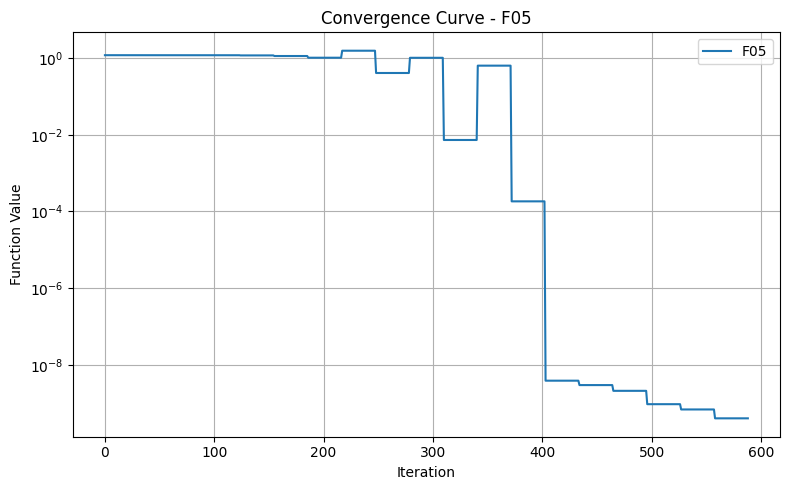

Running F06 (dim=30)...


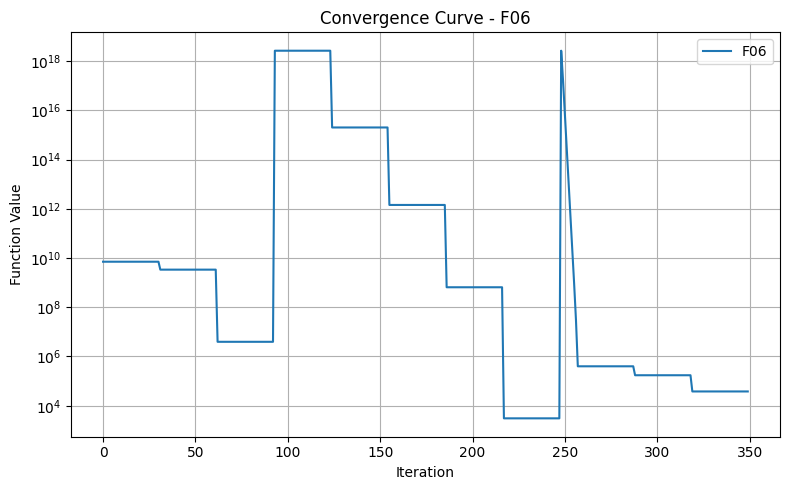

Running F07 (dim=30)...


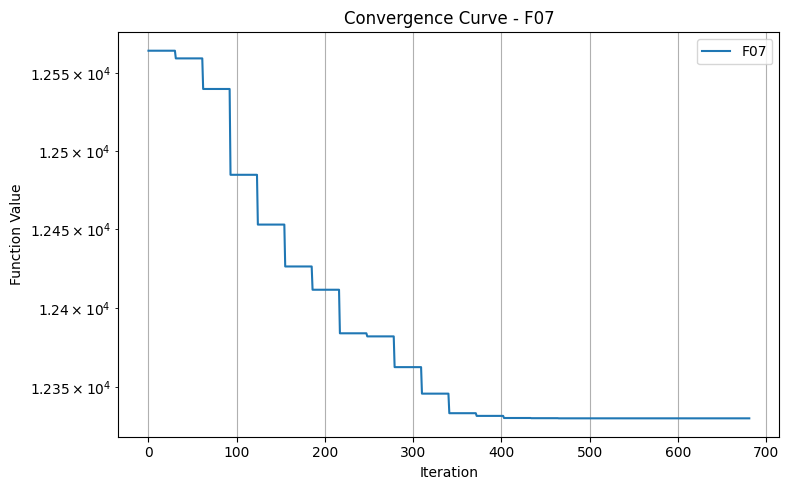

Running F08 (dim=30)...


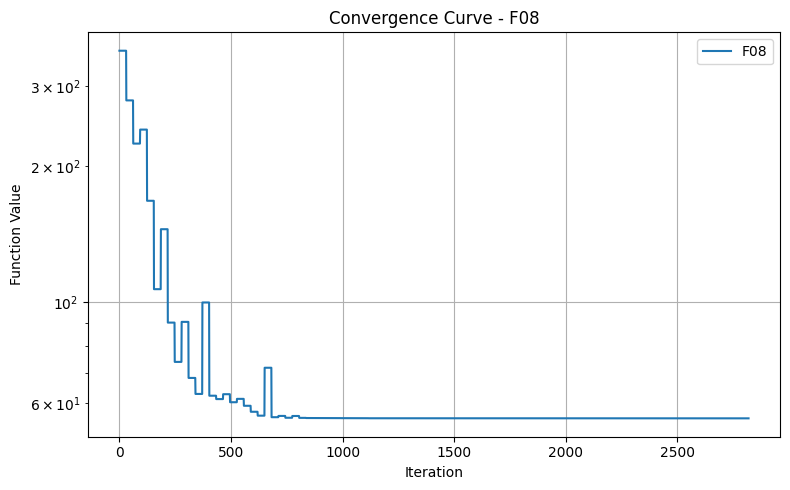

Running F09 (dim=30)...


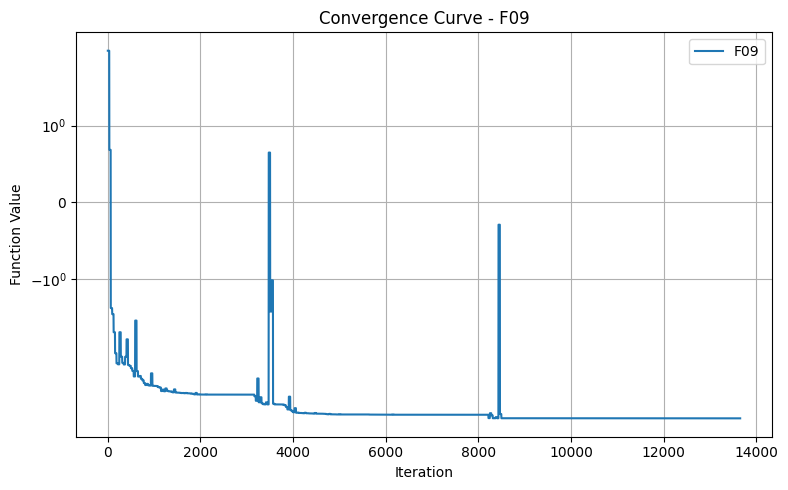

Running F10 (dim=30)...


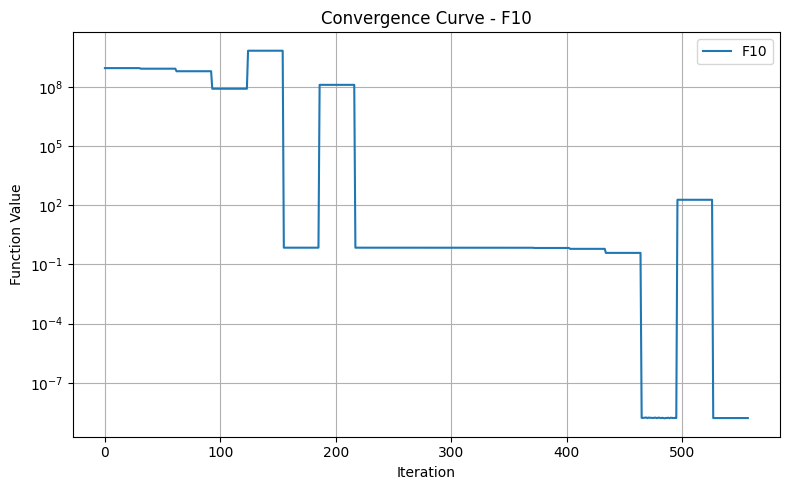

Running F11 (dim=30)...


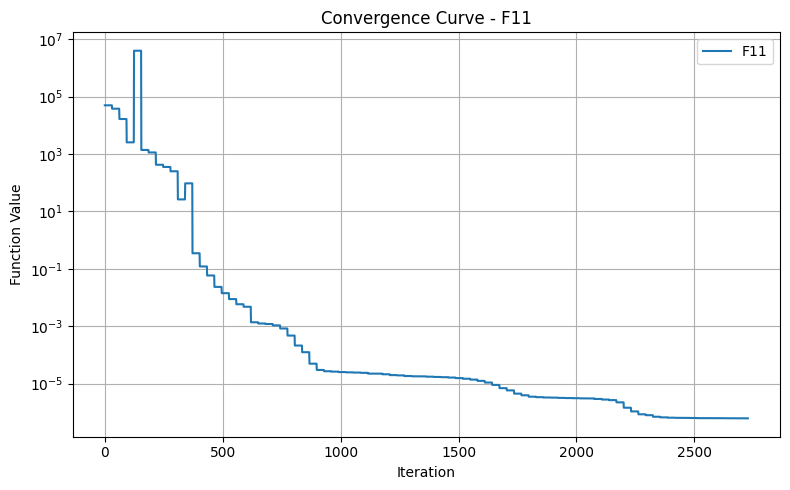

Running F12 (dim=30)...


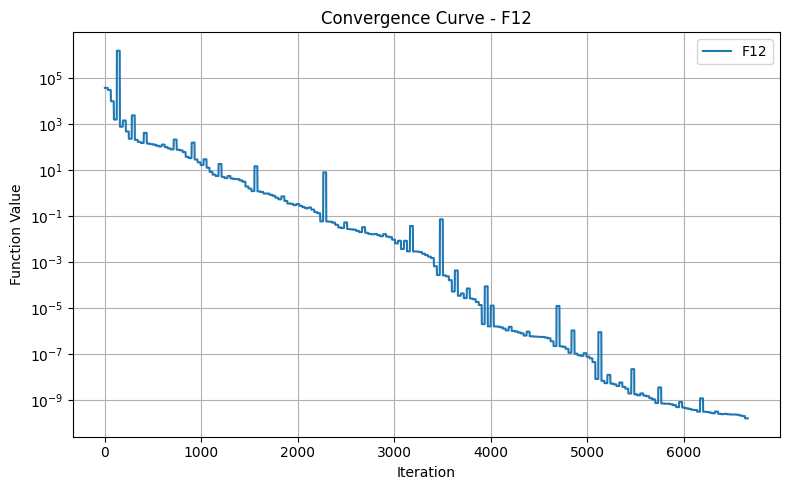

Running F13 (dim=30)...


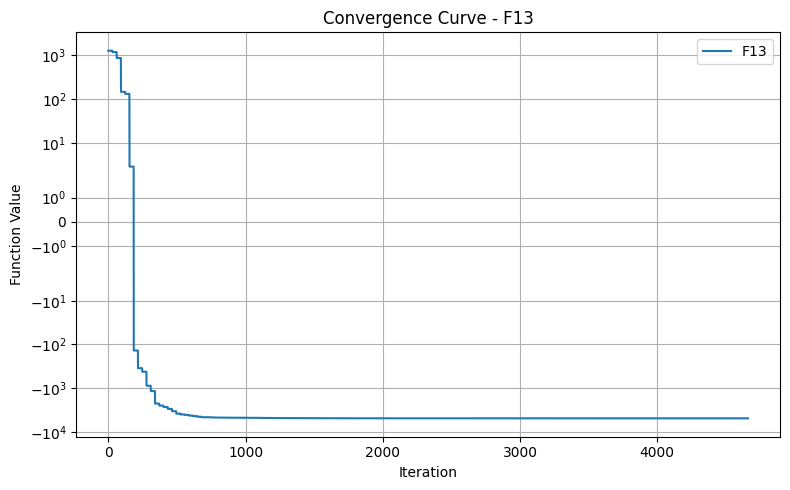

Running F14 (dim=30)...


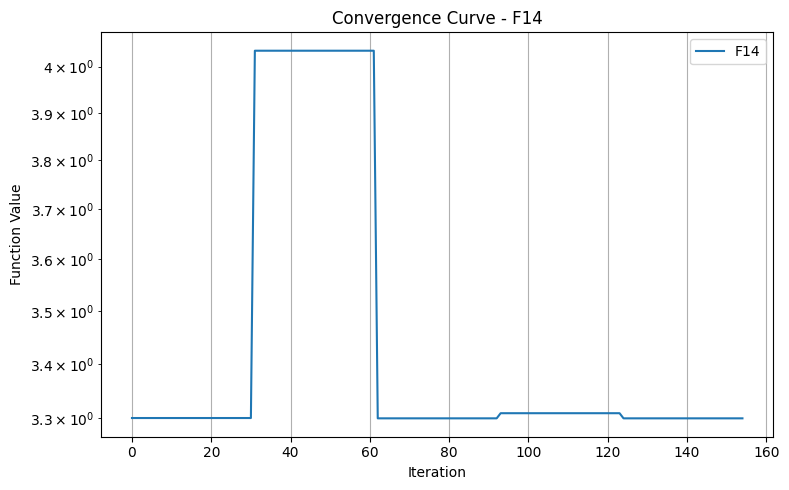

Running F15 (dim=30)...


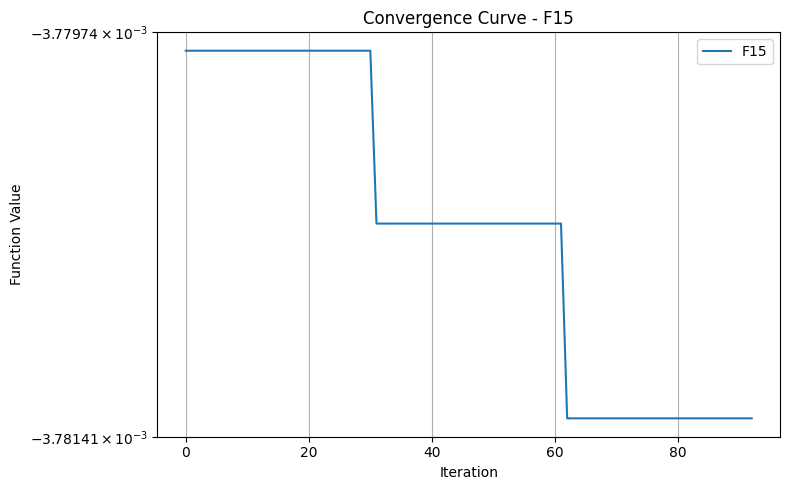

Running F16 (dim=2)...


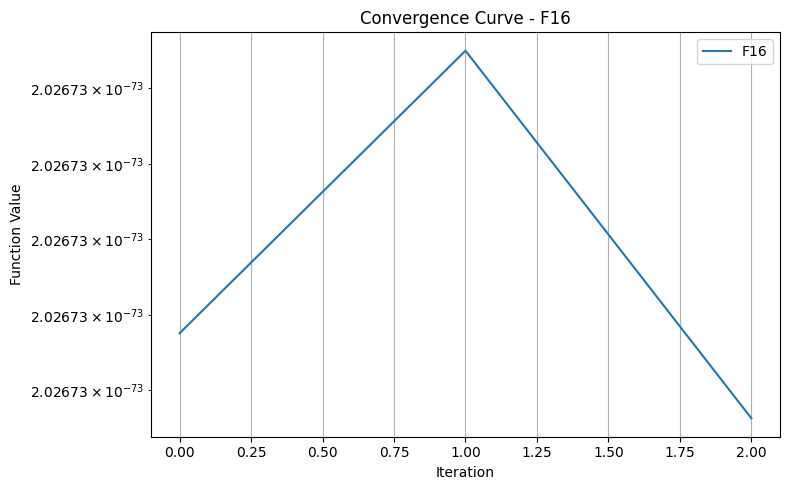

Running F17 (dim=2)...


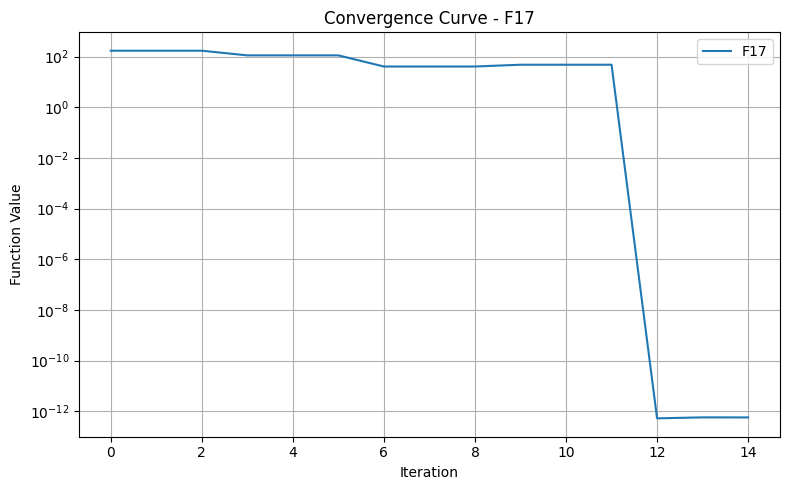

Running F18 (dim=2)...


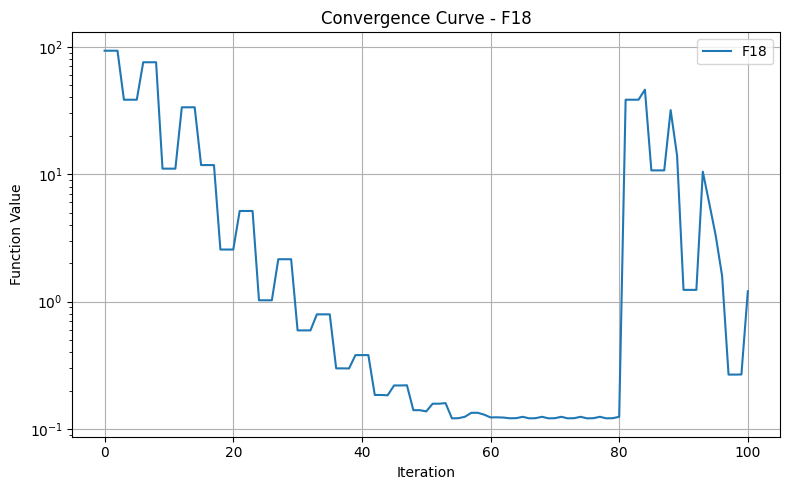

Running F19 (dim=2)...


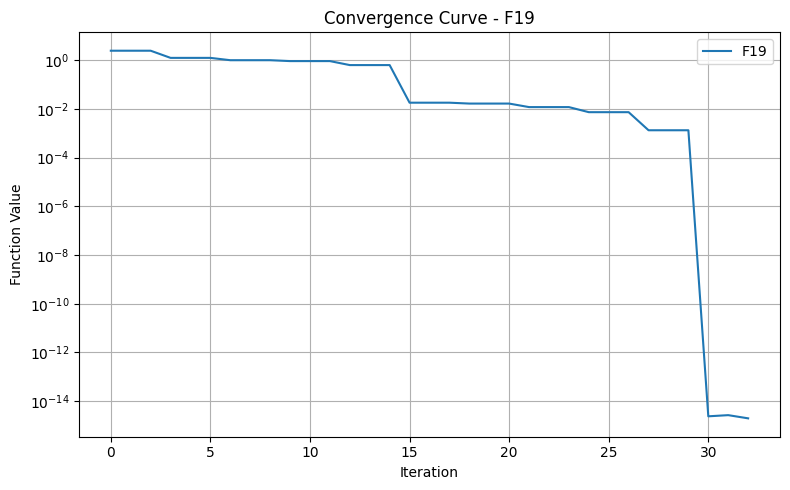

Running F20 (dim=2)...


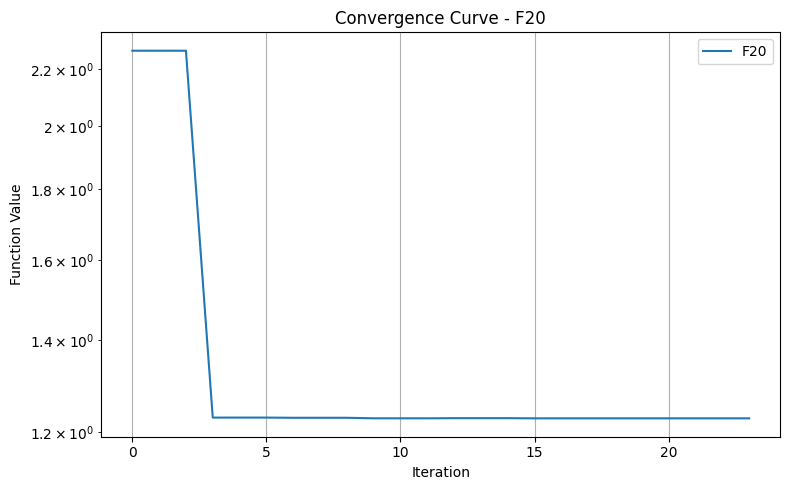

Running F21 (dim=2)...


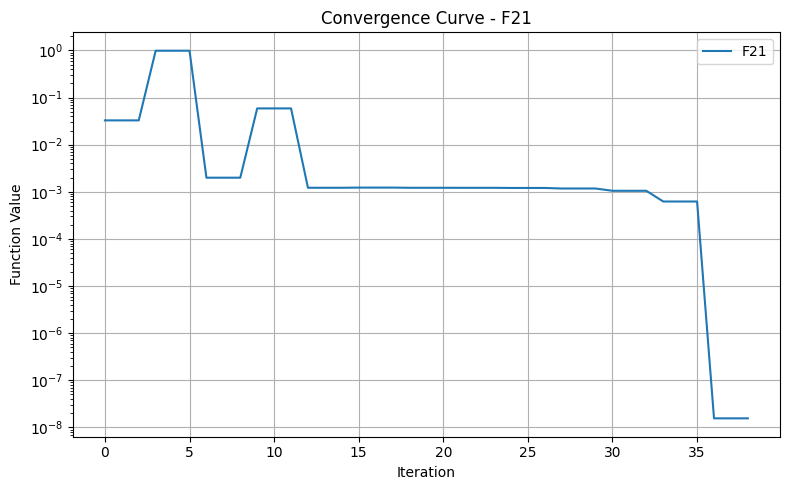

Running F22 (dim=2)...


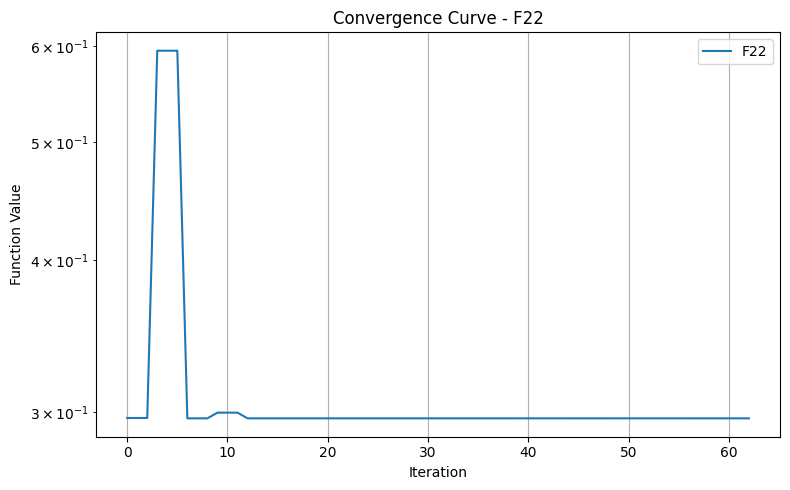

Running F23 (dim=2)...


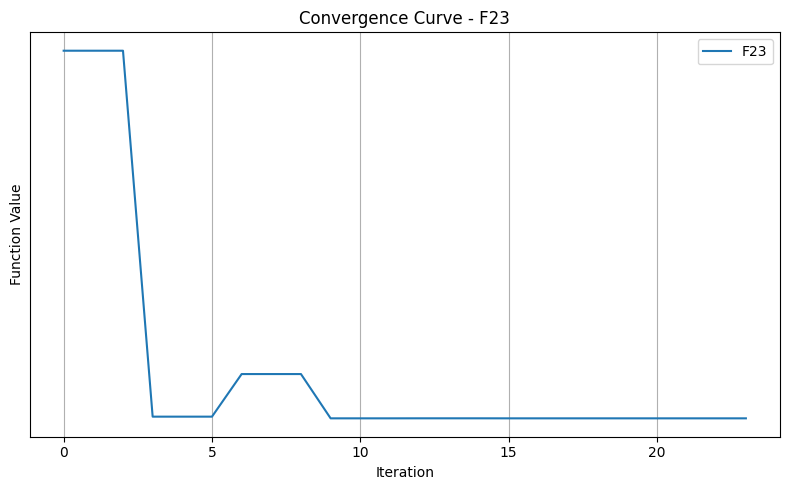


--- Benchmark Results ---
                  Best          Mean        Median         Worst           STD
Function                                                                      
F01       1.483439e-15  6.905013e-13  1.129845e-14  4.643897e-12  1.250508e-12
F02       4.276787e-12  5.315498e-01  1.722050e-10  3.986624e+00  1.355192e+00
F03       6.586469e+02  9.705243e+02  9.810053e+02  1.281468e+03  1.379945e+02
F04       1.153841e+01  1.328329e+01  1.346329e+01  1.470874e+01  7.229445e-01
F05       2.919396e-10  4.516877e-03  7.685703e-10  2.956447e-02  8.295644e-03
F06       1.114082e-12  3.435215e+08  4.179649e+07  4.523981e+09  8.522822e+08
F07       1.218934e+04  1.230077e+04  1.231016e+04  1.237058e+04  4.786196e+01
F08       2.875591e+01  5.319893e+01  5.382237e+01  7.946275e+01  1.095266e+01
F09      -8.606015e+00 -6.374701e+00 -6.378424e+00 -3.637850e+00  1.051516e+00
F10       6.411798e-10  7.204630e-07  1.609824e-09  1.950239e-05  3.503933e-06
F11       3.030181e-09  1

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# --- Benchmark Functions (F1–F23) ---
def F1(x): return np.sum(x**2)
def F2(x): return np.sum(100 * (x[1:] - x[:-1]**2)**2 + (x[:-1] - 1)**2)
def F3(x): return np.sum(x**2 - 10 * np.cos(2 * np.pi * x) + 10)
def F4(x): return -20 * np.exp(-0.2*np.sqrt(np.mean(x**2))) - np.exp(np.mean(np.cos(2*np.pi*x))) + 20 + np.e
def F5(x): return np.sum(x**2)/4000 - np.prod(np.cos(x / np.sqrt(np.arange(1, len(x)+1)))) + 1
def F6(x): return np.sum(x**2) + (np.sum(0.5 * np.arange(1, len(x)+1) * x))**2 + (np.sum(0.5 * np.arange(1, len(x)+1) * x))**4
def F7(x): return 418.9829 * len(x) - np.sum(x * np.sin(np.sqrt(np.abs(x))))
def F8(x): 
    w = 1 + (x - 1) / 4
    return np.sin(np.pi * w[0])**2 + np.sum((w[:-1] - 1)**2 * (1 + 10*np.sin(np.pi*w[:-1] + 1)**2)) + (w[-1]-1)**2 * (1 + np.sin(2*np.pi*w[-1])**2)
def F9(x): return -np.sum(np.sin(x) * np.sin(((np.arange(1, len(x)+1) * x**2) / np.pi))**20)
def F10(x): return x[0]**2 + 1e6 * np.sum(x[1:]**2)
def F11(x): return np.sum(np.abs(x)**(2 + 4*np.arange(len(x))/(len(x)-1)))
def F12(x): return np.sum([np.sum(x[:i])**2 for i in range(1, len(x)+1)])
def F13(x): return np.sum((x - 1)**2) - np.sum(x[:-1] * x[1:])
def F14(x): return 1 - np.cos(2*np.pi*np.sqrt(np.sum(x**2))) + 0.1*np.sqrt(np.sum(x**2))
def F15(x): return - (1 + np.cos(12*np.sqrt(np.sum(x**2)))) / (0.5*np.sum(x**2) + 2)
def F16(x): return -np.cos(x[0]) * np.cos(x[1]) * np.exp(-(x[0]-np.pi)**2 - (x[1]-np.pi)**2)
def F17(x): return (x[0] + 2*x[1] - 7)**2 + (2*x[0] + x[1] - 5)**2
def F18(x): return 100*np.sqrt(abs(x[1] - 0.01*x[0]**2)) + 0.01*abs(x[0] + 10)
def F19(x): return 0.26*(x[0]**2 + x[1]**2) - 0.48*x[0]*x[1]
def F20(x): return np.sin(x[0]+x[1]) + (x[0]-x[1])**2 - 1.5*x[0] + 2.5*x[1] + 1
def F21(x): return 0.5 + (np.sin(x[0]**2 - x[1]**2)**2 - 0.5)/(1 + 0.001*(x[0]**2 + x[1]**2))**2
def F22(x): return 0.5 + (np.cos(np.sin(abs(x[0]**2 - x[1]**2)))**2 - 0.5)/(1 + 0.001*(x[0]**2 + x[1]**2))**2
def F23(x): 
    r = np.sqrt(x[0]**2 + x[1]**2)
    z = np.clip(abs(1 - r / np.pi), -50, 50)
    try:
        exp_term = np.exp(z)
    except:
        exp_term = 1e10
    return -abs(np.sin(x[0]) * np.cos(x[1]) * exp_term)

benchmark_functions = {
    f"F{str(i+1).zfill(2)}": f for i, f in enumerate([
        F1, F2, F3, F4, F5, F6, F7, F8, F9, F10, F11, F12, F13, F14, F15,
        F16, F17, F18, F19, F20, F21, F22, F23
    ])
}

# ----- CG -----
def cg(func, initial_guess):
    convergence_curve = []

    def wrapped_func(x):
        val = func(x)
        convergence_curve.append(val)
        return val

    result = minimize(
        fun=wrapped_func,
        x0=initial_guess,
        method='CG',
        constraints=[],
        options={'maxiter': 1000, 'disp': False}
    )
    return result.x, result.fun, convergence_curve

# ----- Run Single Benchmark -----
def run_benchmark(func, dim, runs=30, low=-10, high=10):
    results = []
    convergence = None
    for _ in range(runs):
        x0 = np.random.uniform(low, high, size=dim)
        try:
            result, val, curve = cg(func, x0)
            if np.isfinite(val):
                results.append(val)
                if convergence is None or (len(curve) < len(convergence)):
                    convergence = curve
        except Exception as e:
            print(f"[!] Error during benchmark run: {e}")
            results.append(np.nan)
    return {
        'Best': np.nanmin(results),
        'Mean': np.nanmean(results),
        'Median': np.nanmedian(results),
        'Worst': np.nanmax(results),
        'STD': np.nanstd(results),
        'Convergence': convergence
    }

# --- Run All Benchmarks with Plotting ---
def run_all_benchmarks(dim=30, runs=30):
    summary = []
    for name, func in benchmark_functions.items():
        d = 2 if name in ['F16','F17','F18','F19','F20','F21','F22','F23'] else dim
        print(f"Running {name} (dim={d})...")
        stats = run_benchmark(func, dim=d, runs=runs)
        convergence = stats.pop('Convergence')

        if convergence:
            plt.figure(figsize=(8, 5))
            plt.plot(convergence, label=name)
            if all(val > 0 for val in convergence):
                plt.yscale('log')
            else:
                plt.yscale('symlog')
            plt.xlabel('Iteration')
            plt.ylabel('Function Value')
            plt.title(f'Convergence Curve - {name}')
            plt.grid(True)
            plt.legend()
            plt.tight_layout()
            plt.show()

        stats['Function'] = name
        summary.append(stats)
    return pd.DataFrame(summary).set_index("Function")

# --- Execute All ---
results = run_all_benchmarks(dim=30, runs=30)
print("\n--- Benchmark Results ---")
print(results)

# Save Excel
results.to_excel('Benchmark_CG.xlsx')
print("\n✅ Results saved to Benchmark_CG.xlsx")